In [ ]:
import json
from pathlib import Path
from pprint import pprint


PROJECT_ROOT = Path(
    "/CNN_with_DSM"
)

CONFIG_PATH = PROJECT_ROOT / "data" / "data-config.json"


def main() -> None:
    if not CONFIG_PATH.exists():
        print(f"Config file not found:\n{CONFIG_PATH}")
        return

    try:
        with CONFIG_PATH.open("r", encoding="utf-8") as file:
            config = json.load(file)

        pprint(config, sort_dicts=False)

    except json.JSONDecodeError as error:
        print(f"Invalid JSON format: {error}")

    except OSError as error:
        print(f"Could not open the config file: {error}")


if __name__ == "__main__":
    main()

{'Image IDs': {'Train Image IDs': [1, 3, 5, 7, 13, 17, 21, 23, 26, 32, 37],
               'Test Image IDs': [11, 15, 28, 30, 34]},
 'Class Names': {'0': 'Impervious surfaces',
                 '1': 'Building',
                 '2': 'Low vegetation',
                 '3': 'Tree',
                 '4': 'Car',
                 '5': 'Clutter/background'},
 'Class Color Codes': {'0': [255, 255, 255],
                       '1': [0, 0, 255],
                       '2': [0, 255, 255],
                       '3': [0, 255, 0],
                       '4': [255, 255, 0],
                       '5': [255, 0, 0]}}


In [12]:
path = "."

DATASET SUMMARY
Multispectral files : 33
nDSM files          : 33
Label files         : 16
Matched samples     : 16

------------------------------------------------------------
Area 1
Multispectral: top_mosaic_09cm_area1.tif
nDSM:          dsm_09cm_matching_area1_normalized.jpg
Label:         top_mosaic_09cm_area1.tif
Label shape:   (2569, 1919, 3)
Number of classes: 6
Class values: [0 1 2 3 4 5]


./.venv/lib/python3.13/site-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)



------------------------------------------------------------
Area 3
Multispectral: top_mosaic_09cm_area3.tif
nDSM:          dsm_09cm_matching_area3_normalized.jpg
Label:         top_mosaic_09cm_area3.tif
Label shape:   (3007, 2006, 3)
Number of classes: 5
Class values: [0 1 2 3 4]


./.venv/lib/python3.13/site-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)



------------------------------------------------------------
Area 5
Multispectral: top_mosaic_09cm_area5.tif
nDSM:          dsm_09cm_matching_area5_normalized.jpg
Label:         top_mosaic_09cm_area5.tif
Label shape:   (2557, 1887, 3)
Number of classes: 5
Class values: [0 1 2 3 4]


./.venv/lib/python3.13/site-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


... (9 outputs left out)

./.venv/lib/python3.13/site-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)



------------------------------------------------------------
Area 21
Multispectral: top_mosaic_09cm_area21.tif
nDSM:          dsm_09cm_matching_area21_normalized.jpg
Label:         top_mosaic_09cm_area21.tif
Label shape:   (2546, 1903, 3)
Number of classes: 5
Class values: [0 1 2 3 4]


./.venv/lib/python3.13/site-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)



------------------------------------------------------------
Area 23
Multispectral: top_mosaic_09cm_area23.tif
nDSM:          dsm_09cm_matching_area23_normalized.jpg
Label:         top_mosaic_09cm_area23.tif
Label shape:   (2546, 1903, 3)
Number of classes: 6
Class values: [0 1 2 3 4 5]


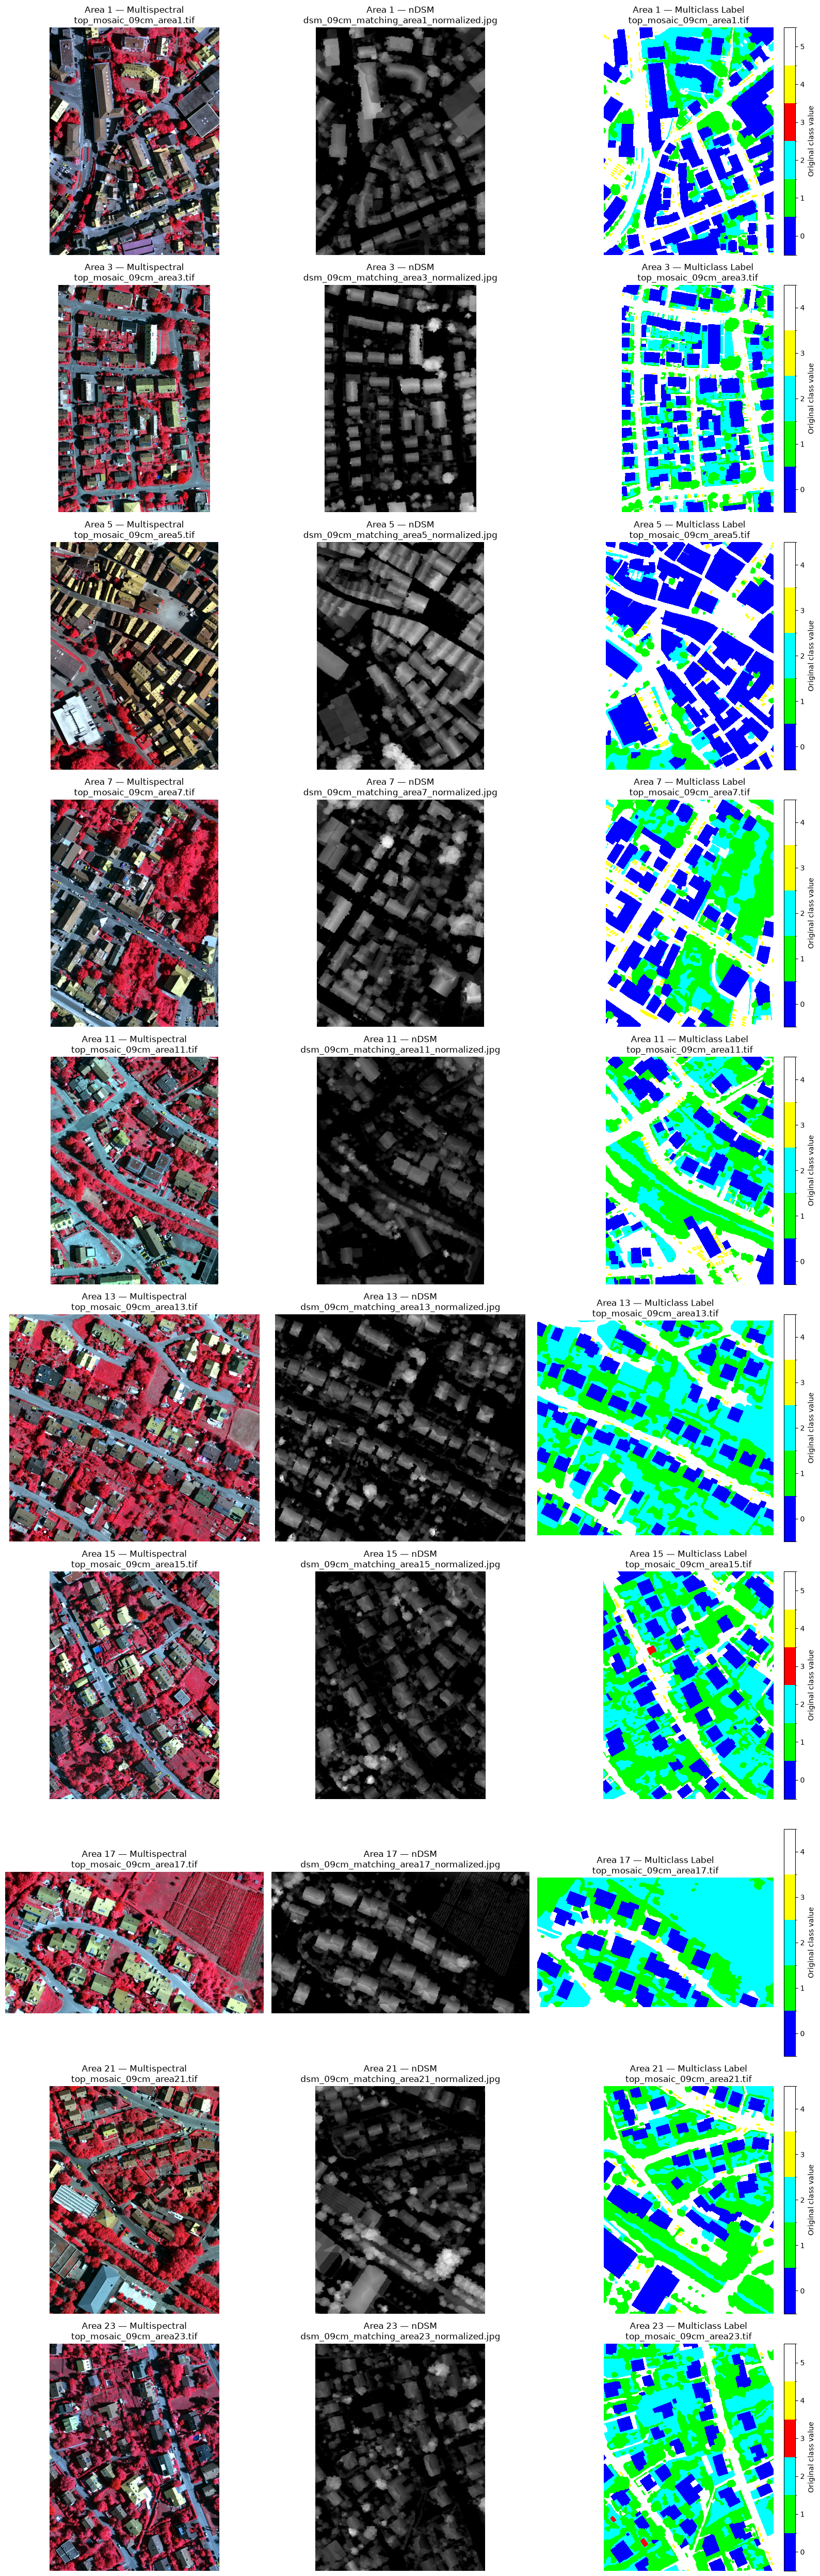

In [18]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import rasterio
from matplotlib.colors import BoundaryNorm, ListedColormap
from PIL import Image


# ============================================================
# 1. PROJECT PATHS
# ============================================================

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "data-config.json").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

MS_FOLDER = PROJECT_ROOT / "data" / "mspectral-images"
DSM_FOLDER = PROJECT_ROOT / "data" / "ndsm-images"
LABEL_FOLDER = PROJECT_ROOT / "data" / "labels"

NUMBER_OF_SAMPLES = 10


# ============================================================
# 2. EXTRACT AREA NUMBER
# ============================================================

def extract_area_number(file_path: Path) -> int | None:
    """
    Extract area number from filenames.

    Examples:
        top_mosaic_09cm_area1.tif
        dsm_09cm_matching_area1_normalized.jpg
    """
    match = re.search(
        r"area[_-]?(\d+)(?!\d)",
        file_path.stem,
        flags=re.IGNORECASE,
    )

    return int(match.group(1)) if match else None


# ============================================================
# 3. CREATE FILE MAPPING
# ============================================================

def create_file_mapping(
    folder: Path,
    allowed_extensions: tuple[str, ...],
) -> dict[int, Path]:
    """
    Create mapping:

        area_number -> file_path
    """
    if not folder.exists():
        raise FileNotFoundError(f"Folder does not exist:\n{folder}")

    mapping = {}

    for file_path in sorted(folder.iterdir()):
        if not file_path.is_file():
            continue

        if file_path.suffix.lower() not in allowed_extensions:
            continue

        area_number = extract_area_number(file_path)

        if area_number is None:
            print(f"Could not extract area number: {file_path.name}")
            continue

        if area_number in mapping:
            print(
                f"Duplicate area {area_number} in {folder.name}: "
                f"{file_path.name}"
            )
            continue

        mapping[area_number] = file_path

    return mapping


# ============================================================
# 4. NORMALIZE MULTISPECTRAL IMAGE
# ============================================================

def normalize_rgb(image: np.ndarray) -> np.ndarray:
    """
    Percentile normalization for visualization.
    """
    image = image.astype(np.float32)

    lower = np.percentile(
        image,
        2,
        axis=(0, 1),
        keepdims=True,
    )

    upper = np.percentile(
        image,
        98,
        axis=(0, 1),
        keepdims=True,
    )

    normalized = (image - lower) / (upper - lower + 1e-8)

    return np.clip(normalized, 0, 1)


# ============================================================
# 5. READ MULTISPECTRAL IMAGE
# ============================================================

def read_multispectral(file_path: Path) -> np.ndarray:
    """
    Read multispectral image and prepare three channels
    for visualization.
    """
    with rasterio.open(file_path) as src:
        image = src.read()

    # Convert:
    # (bands, height, width) -> (height, width, bands)
    image = np.moveaxis(image, 0, -1)

    if image.shape[-1] < 3:
        raise ValueError(
            f"Image contains fewer than three bands:\n{file_path}"
        )

    # Change the band order here when necessary.
    #
    # Example:
    # rgb = image[:, :, [2, 1, 0]]
    #
    # Current false-colour appearance:
    rgb = image[:, :, :3]

    return normalize_rgb(rgb)


# ============================================================
# 6. READ DSM
# ============================================================

def read_dsm(file_path: Path) -> np.ndarray:
    """
    Read DSM/nDSM without changing its numerical values.
    """
    if file_path.suffix.lower() in {".jpg", ".jpeg", ".png"}:
        with Image.open(file_path) as image:
            return np.asarray(image)

    with rasterio.open(file_path) as src:
        return src.read(1)


# ============================================================
# 7. READ MULTICLASS LABEL
# ============================================================

def read_label(file_path: Path) -> np.ndarray:
    """
    Read a multiclass segmentation label.

    The function does not normalize the label and does not
    convert it to grayscale unless the original label is
    already single-band.
    """
    if file_path.suffix.lower() in {".jpg", ".jpeg", ".png"}:
        with Image.open(file_path) as image:
            label = np.asarray(image)
    else:
        with rasterio.open(file_path) as src:
            label = src.read()

        # Single-band label:
        # (1, height, width) -> (height, width)
        if label.shape[0] == 1:
            label = label[0]

        # Multi-band RGB label:
        # (bands, height, width) -> (height, width, bands)
        else:
            label = np.moveaxis(label, 0, -1)

    return label


# ============================================================
# 8. CONVERT RGB LABEL TO CLASS IDS
# ============================================================

def rgb_label_to_class_ids(
    rgb_label: np.ndarray,
) -> tuple[np.ndarray, np.ndarray]:
    """
    Convert an RGB colour-coded label into integer class IDs.

    Returns:
        class_mask:
            2D array containing values 0, 1, 2, ...

        class_colors:
            RGB colour associated with each class
    """
    if rgb_label.ndim != 3:
        raise ValueError("RGB label must have three dimensions.")

    # Remove alpha channel if present
    rgb_label = rgb_label[:, :, :3]

    height, width, channels = rgb_label.shape

    pixels = rgb_label.reshape(-1, channels)

    unique_colors, inverse_indices = np.unique(
        pixels,
        axis=0,
        return_inverse=True,
    )

    class_mask = inverse_indices.reshape(height, width)

    return class_mask, unique_colors


# ============================================================
# 9. PREPARE LABEL FOR DISPLAY
# ============================================================

def prepare_label_for_display(
    label: np.ndarray,
) -> tuple[np.ndarray, np.ndarray, ListedColormap, BoundaryNorm]:
    """
    Prepare either:

    1. Single-band class IDs
    2. RGB colour-coded labels

    for categorical display.
    """
    # --------------------------------------------------------
    # RGB/RGBA colour-coded label
    # --------------------------------------------------------

    if label.ndim == 3:
        class_mask, original_colors = rgb_label_to_class_ids(label)

        # Convert colours from 0-255 to 0-1
        colors = original_colors.astype(np.float32)

        if colors.max() > 1:
            colors = colors / 255.0

        class_values = np.arange(len(original_colors))

        categorical_cmap = ListedColormap(colors)

        boundaries = np.arange(
            len(class_values) + 1
        ) - 0.5

        categorical_norm = BoundaryNorm(
            boundaries,
            categorical_cmap.N,
        )

        return (
            class_mask,
            class_values,
            categorical_cmap,
            categorical_norm,
        )

    # --------------------------------------------------------
    # Single-band class ID label
    # --------------------------------------------------------

    class_values = np.unique(label)

    # Convert arbitrary values such as:
    # [0, 50, 100, 150, 255]
    #
    # into display indices:
    # [0, 1, 2, 3, 4]
    display_mask = np.zeros(
        label.shape,
        dtype=np.int32,
    )

    for display_id, class_value in enumerate(class_values):
        display_mask[label == class_value] = display_id

    # tab20 supports up to 20 clearly distinct categories
    base_cmap = plt.get_cmap(
        "tab20",
        len(class_values),
    )

    categorical_cmap = ListedColormap(
        base_cmap(np.arange(len(class_values)))
    )

    boundaries = np.arange(
        len(class_values) + 1
    ) - 0.5

    categorical_norm = BoundaryNorm(
        boundaries,
        categorical_cmap.N,
    )

    return (
        display_mask,
        class_values,
        categorical_cmap,
        categorical_norm,
    )


# ============================================================
# 10. CHECK IMAGE SHAPES
# ============================================================

def check_shapes(
    multispectral: np.ndarray,
    dsm: np.ndarray,
    label: np.ndarray,
    area_number: int,
) -> None:
    """
    Check whether all corresponding files have equal spatial
    dimensions.
    """
    multispectral_shape = multispectral.shape[:2]
    dsm_shape = dsm.shape[:2]
    label_shape = label.shape[:2]

    if (
        multispectral_shape != dsm_shape
        or multispectral_shape != label_shape
    ):
        print(f"\nShape warning for area {area_number}")
        print(f"Multispectral: {multispectral_shape}")
        print(f"nDSM:          {dsm_shape}")
        print(f"Label:         {label_shape}")


# ============================================================
# 11. MAIN
# ============================================================

def main() -> None:
    ms_files = create_file_mapping(
        MS_FOLDER,
        allowed_extensions=(".tif", ".tiff"),
    )

    dsm_files = create_file_mapping(
        DSM_FOLDER,
        allowed_extensions=(
            ".tif",
            ".tiff",
            ".jpg",
            ".jpeg",
            ".png",
        ),
    )

    label_files = create_file_mapping(
        LABEL_FOLDER,
        allowed_extensions=(
            ".tif",
            ".tiff",
            ".jpg",
            ".jpeg",
            ".png",
        ),
    )

    # Keep only corresponding samples available in all folders
    common_areas = sorted(
        set(ms_files)
        & set(dsm_files)
        & set(label_files)
    )

    print("=" * 60)
    print("DATASET SUMMARY")
    print("=" * 60)
    print(f"Multispectral files : {len(ms_files)}")
    print(f"nDSM files          : {len(dsm_files)}")
    print(f"Label files         : {len(label_files)}")
    print(f"Matched samples     : {len(common_areas)}")

    if not common_areas:
        raise RuntimeError(
            "No corresponding multispectral, nDSM and label "
            "files were found."
        )

    number_to_display = min(
        NUMBER_OF_SAMPLES,
        len(common_areas),
    )

    selected_areas = common_areas[:number_to_display]

    fig, axes = plt.subplots(
        nrows=number_to_display,
        ncols=3,
        figsize=(16, 5 * number_to_display),
    )

    axes = np.atleast_2d(axes)

    for row, area_number in enumerate(selected_areas):
        ms_path = ms_files[area_number]
        dsm_path = dsm_files[area_number]
        label_path = label_files[area_number]

        multispectral = read_multispectral(ms_path)
        dsm = read_dsm(dsm_path)
        label = read_label(label_path)

        check_shapes(
            multispectral=multispectral,
            dsm=dsm,
            label=label,
            area_number=area_number,
        )

        (
            label_display,
            class_values,
            label_cmap,
            label_norm,
        ) = prepare_label_for_display(label)

        print("\n" + "-" * 60)
        print(f"Area {area_number}")
        print(f"Multispectral: {ms_path.name}")
        print(f"nDSM:          {dsm_path.name}")
        print(f"Label:         {label_path.name}")
        print(f"Label shape:   {label.shape}")
        print(f"Number of classes: {len(class_values)}")
        print(f"Class values: {class_values}")

        # ----------------------------------------------------
        # Multispectral
        # ----------------------------------------------------

        axes[row, 0].imshow(multispectral)
        axes[row, 0].set_title(
            f"Area {area_number} — Multispectral\n"
            f"{ms_path.name}"
        )
        axes[row, 0].axis("off")

        # ----------------------------------------------------
        # nDSM
        # ----------------------------------------------------

        axes[row, 1].imshow(
            dsm,
            cmap="gray",
        )
        axes[row, 1].set_title(
            f"Area {area_number} — nDSM\n"
            f"{dsm_path.name}"
        )
        axes[row, 1].axis("off")

        # ----------------------------------------------------
        # Multiclass label
        # ----------------------------------------------------

        label_plot = axes[row, 2].imshow(
            label_display,
            cmap=label_cmap,
            norm=label_norm,
            interpolation="nearest",
        )

        axes[row, 2].set_title(
            f"Area {area_number} — Multiclass Label\n"
            f"{label_path.name}"
        )
        axes[row, 2].axis("off")

        # Add one colorbar for this label
        colorbar = fig.colorbar(
            label_plot,
            ax=axes[row, 2],
            fraction=0.046,
            pad=0.04,
            ticks=np.arange(len(class_values)),
        )

        colorbar.ax.set_yticklabels(
            [str(value) for value in class_values]
        )

        colorbar.set_label("Original class value")

    plt.tight_layout()
    plt.show()


# ============================================================
# 12. RUN
# ============================================================

if __name__ == "__main__":
    main()

results_analysis.ipynb


In [ ]:

import json
import re
from pathlib import Path

path = Path("/data/data-config.json")

with path.open("r", encoding="utf-8") as file:
    config = json.load(file)


def inspect(value, path="root"):
    if isinstance(value, dict):
        for key, child in value.items():
            inspect(child, f"{path}.{key}")

    elif isinstance(value, list):
        for index, child in enumerate(value):
            inspect(child, f"{path}[{index}]")

    elif isinstance(value, str):
        if re.search(r"area[\s_-]*\d+", value, flags=re.IGNORECASE):
            print(f"{path}: {value}")



inspect(config)

In [26]:
inspect(config)

In [30]:
from pathlib import Path

import pandas as pd


PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "data-config.json").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

METADATA_FOLDER = PROJECT_ROOT / "metadata"

TRAIN_CSV = METADATA_FOLDER / "train_patches.csv"
VALIDATION_CSV = METADATA_FOLDER / "validation_patches.csv"
TEST_CSV = METADATA_FOLDER / "test_patches.csv"


def read_csv_file(csv_path: Path) -> pd.DataFrame:
    """Read a CSV file after checking that it exists."""
    if not csv_path.exists():
        raise FileNotFoundError(f"CSV file not found:\n{csv_path}")

    return pd.read_csv(csv_path)


def print_dataset_information(
    name: str,
    dataframe: pd.DataFrame,
) -> None:
    """Print patch count and unique area IDs."""
    print(f"\n{name}")
    print("-" * 50)
    print(f"Number of patches: {len(dataframe)}")

    if "area_id" in dataframe.columns:
        area_ids = sorted(dataframe["area_id"].dropna().unique())
        print(f"Number of areas: {len(area_ids)}")
        print(f"Areas: {area_ids}")
    else:
        print("Column 'area_id' was not found.")
        print(f"Available columns: {dataframe.columns.tolist()}")


def main() -> None:
    train_patches = read_csv_file(TRAIN_CSV)
    validation_patches = read_csv_file(VALIDATION_CSV)
    test_patches = read_csv_file(TEST_CSV)

    print("=" * 60)
    print("PATCH DATASET SUMMARY")
    print("=" * 60)

    print_dataset_information(
        name="Training dataset",
        dataframe=train_patches,
    )

    print_dataset_information(
        name="Validation dataset",
        dataframe=validation_patches,
    )

    print_dataset_information(
        name="Test dataset",
        dataframe=test_patches,
    )

    print("\nFirst five training patches")
    print("-" * 50)
    print(train_patches.head())

    print("\nCSV columns")
    print("-" * 50)
    print(train_patches.columns.tolist())


if __name__ == "__main__":
    main()

PATCH DATASET SUMMARY

Training dataset
--------------------------------------------------
Number of patches: 752
Number of areas: 9
Areas: ['area1', 'area13', 'area17', 'area21', 'area23', 'area26', 'area32', 'area5', 'area7']

Validation dataset
--------------------------------------------------
Number of patches: 160
Number of areas: 2
Areas: ['area3', 'area37']

Test dataset
--------------------------------------------------
Number of patches: 412
Number of areas: 5
Areas: ['area11', 'area15', 'area28', 'area30', 'area34']

First five training patches
--------------------------------------------------
                    patch_id  split area_id  row  column  patch_height  \
0  train_area1_r00000_c00000  train   area1    0       0           256   
1  train_area1_r00000_c00256  train   area1    0     256           256   
2  train_area1_r00000_c00512  train   area1    0     512           256   
3  train_area1_r00000_c00768  train   area1    0     768           256   
4  train_area1_r0